In [60]:
import pandas as pd

print("Pandas is working!")

Pandas is working!


In [61]:
from pathlib import Path

data_folder = Path("../data/raw")

print("Files found:")
for file in data_folder.iterdir():
    print(file.name)

Files found:
settles.acl16.learning_traces.13m.csv.gz


In [62]:
dataset_path = "../data/raw/settles.acl16.learning_traces.13m.csv.gz"

df_sample = pd.read_csv(
    dataset_path,
    compression="gzip",
    nrows=10
)

df_sample

,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.00,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.50,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.00,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.50,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.00,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1
5,1.00,1362076081,27649635,u:FO,de,en,56429751fdaedb6e491f4795c770f5a4,der/der<det><def><m><sg><nom>,4,3,1,1
6,1.00,1362076081,27649635,u:FO,de,en,1bacf218eaaf9f944e525f7be9b31899,kind/kind<n><nt><sg><nom>,4,4,1,1
7,1.00,1362082032,444407,u:dDwF,es,en,73eecb492ca758ddab5371cf7b5cca32,bajo/bajo<pr>,3,3,1,1
8,1.00,1362082044,5963,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,8,6,6,6
9,0.75,1362082044,5963,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,6,5,4,3


In [63]:
df = pd.read_csv(
    dataset_path,
    compression="gzip",
    nrows=10000
)

print("Rows:", len(df))
print("Columns:", len(df.columns))

df.info()

Rows: 10000
Columns: 12
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   p_recall           10000 non-null  float64
 1   timestamp          10000 non-null  int64  
 2   delta              10000 non-null  int64  
 3   user_id            10000 non-null  str    
 4   learning_language  10000 non-null  str    
 5   ui_language        10000 non-null  str    
 6   lexeme_id          10000 non-null  str    
 7   lexeme_string      10000 non-null  str    
 8   history_seen       10000 non-null  int64  
 9   history_correct    10000 non-null  int64  
 10  session_seen       10000 non-null  int64  
 11  session_correct    10000 non-null  int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 937.6 KB


In [64]:
df.isnull().sum()

p_recall             0
timestamp            0
delta                0
user_id              0
learning_language    0
ui_language          0
lexeme_id            0
lexeme_string        0
history_seen         0
history_correct      0
session_seen         0
session_correct      0
dtype: int64

In [65]:
df.describe()

,p_recall,timestamp,delta,history_seen,history_correct,session_seen,session_correct
count,10000.000000,1.000000e+04,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
mean,0.895510,1.362083e+09,7.594360e+05,22.382900,20.066900,1.777500,1.607200
std,0.272238,2.421320e+02,2.792071e+06,96.950924,86.333063,1.305973,1.273527
min,0.000000,1.362076e+09,1.400000e+01,1.000000,1.000000,1.000000,0.000000
25%,1.000000,1.362083e+09,5.850000e+02,3.000000,3.000000,1.000000,1.000000
50%,1.000000,1.362083e+09,7.179200e+04,7.000000,6.000000,1.000000,1.000000
75%,1.000000,1.362083e+09,3.499520e+05,16.000000,14.000000,2.000000,2.000000
max,1.000000,1.362083e+09,2.764964e+07,2773.000000,2389.000000,16.000000,16.000000


In [66]:
print("Unique users:", df["user_id"].nunique())
print("Unique lexemes:", df["lexeme_id"].nunique())
print("Learning languages:", df["learning_language"].unique())
print("UI languages:", df["ui_language"].unique())

Unique users: 511
Unique lexemes: 2656
Learning languages: <StringArray>
['de', 'es', 'pt', 'en', 'fr', 'it']
Length: 6, dtype: str
UI languages: <StringArray>
['en', 'pt', 'es', 'it']
Length: 4, dtype: str


In [67]:
print("p_recall values:")
print(df["p_recall"].value_counts().sort_index())

print("\nDelta statistics:")
print(df["delta"].describe())

print("\nDelta in seconds:")
print(df["delta"].describe() / 1000)

p_recall values:
p_recall
0.000000     705
0.333333      23
0.400000       4
0.500000     388
0.600000      12
0.666667     208
0.750000     107
0.777778       2
0.800000      78
0.833333      36
0.857143      16
0.875000      10
0.888889       5
0.900000       5
0.909091       1
0.923077       3
0.928571       1
0.933333       2
0.937500       2
1.000000    8392
Name: count, dtype: int64

Delta statistics:
count    1.000000e+04
mean     7.594360e+05
std      2.792071e+06
min      1.400000e+01
25%      5.850000e+02
50%      7.179200e+04
75%      3.499520e+05
max      2.764964e+07
Name: delta, dtype: float64

Delta in seconds:
count       10.000000
mean       759.436043
std       2792.070952
min          0.014000
25%          0.585000
50%         71.792000
75%        349.952000
max      27649.635000
Name: delta, dtype: float64


In [68]:
print("p_recall values:")
print(df["p_recall"].value_counts().sort_index())

print("\nDelta statistics:")
print(df["delta"].describe())

print("\nDelta in seconds:")
print(df["delta"].describe() / 1000)

p_recall values:
p_recall
0.000000     705
0.333333      23
0.400000       4
0.500000     388
0.600000      12
0.666667     208
0.750000     107
0.777778       2
0.800000      78
0.833333      36
0.857143      16
0.875000      10
0.888889       5
0.900000       5
0.909091       1
0.923077       3
0.928571       1
0.933333       2
0.937500       2
1.000000    8392
Name: count, dtype: int64

Delta statistics:
count    1.000000e+04
mean     7.594360e+05
std      2.792071e+06
min      1.400000e+01
25%      5.850000e+02
50%      7.179200e+04
75%      3.499520e+05
max      2.764964e+07
Name: delta, dtype: float64

Delta in seconds:
count       10.000000
mean       759.436043
std       2792.070952
min          0.014000
25%          0.585000
50%         71.792000
75%        349.952000
max      27649.635000
Name: delta, dtype: float64


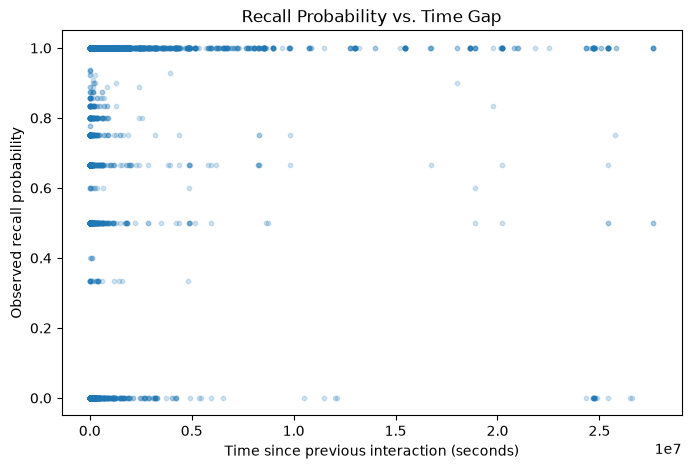

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["delta"],
    df["p_recall"],
    alpha=0.2,
    s=10
)

plt.xlabel("Time since previous interaction (seconds)")
plt.ylabel("Observed recall probability")
plt.title("Recall Probability vs. Time Gap")

plt.show()

In [70]:
print(df[["user_id", "lexeme_id", "timestamp", "delta", "p_recall"]].head(20))

   user_id                         lexeme_id   timestamp     delta  p_recall
0     u:FO  76390c1350a8dac31186187e2fe1e178  1362076081  27649635  1.000000
1     u:FO  7dfd7086f3671685e2cf1c1da72796d7  1362076081  27649635  0.500000
2     u:FO  35a54c25a2cda8127343f6a82e6f6b7d  1362076081  27649635  1.000000
3     u:FO  0cf63ffe3dda158bc3dbd55682b355ae  1362076081  27649635  0.500000
4     u:FO  84920990d78044db53c1b012f5bf9ab5  1362076081  27649635  1.000000
5     u:FO  56429751fdaedb6e491f4795c770f5a4  1362076081  27649635  1.000000
6     u:FO  1bacf218eaaf9f944e525f7be9b31899  1362076081  27649635  1.000000
7   u:dDwF  73eecb492ca758ddab5371cf7b5cca32  1362082032    444407  1.000000
8     u:FO  76390c1350a8dac31186187e2fe1e178  1362082044      5963  1.000000
9     u:FO  7dfd7086f3671685e2cf1c1da72796d7  1362082044      5963  0.750000
10    u:FO  35a54c25a2cda8127343f6a82e6f6b7d  1362082044      5963  0.888889
11    u:FO  0cf63ffe3dda158bc3dbd55682b355ae  1362082044      5963  0.800000

In [71]:
# Make a copy so we don't accidentally modify our original sample
df_model = df.copy()

# Convert time gap from seconds to days
df_model["delta_days"] = df_model["delta"] / (60 * 60 * 24)

# Calculate previous accuracy
df_model["history_accuracy"] = (
    df_model["history_correct"] / df_model["history_seen"]
)

# Calculate current-session accuracy
df_model["session_accuracy"] = (
    df_model["session_correct"] / df_model["session_seen"]
)

df_model[
    [
        "user_id",
        "lexeme_id",
        "delta",
        "delta_days",
        "history_seen",
        "history_correct",
        "history_accuracy",
        "session_seen",
        "session_correct",
        "session_accuracy",
        "p_recall"
    ]
].head(10)

,user_id,lexeme_id,delta,delta_days,history_seen,history_correct,history_accuracy,session_seen,session_correct,session_accuracy,p_recall
0,u:FO,76390c1350a8dac31186187e2fe1e178,27649635,320.018924,6,4,0.666667,2,2,1.00,1.00
1,u:FO,7dfd7086f3671685e2cf1c1da72796d7,27649635,320.018924,4,4,1.000000,2,1,0.50,0.50
2,u:FO,35a54c25a2cda8127343f6a82e6f6b7d,27649635,320.018924,5,4,0.800000,1,1,1.00,1.00
3,u:FO,0cf63ffe3dda158bc3dbd55682b355ae,27649635,320.018924,6,5,0.833333,2,1,0.50,0.50
4,u:FO,84920990d78044db53c1b012f5bf9ab5,27649635,320.018924,4,4,1.000000,1,1,1.00,1.00
5,u:FO,56429751fdaedb6e491f4795c770f5a4,27649635,320.018924,4,3,0.750000,1,1,1.00,1.00
6,u:FO,1bacf218eaaf9f944e525f7be9b31899,27649635,320.018924,4,4,1.000000,1,1,1.00,1.00
7,u:dDwF,73eecb492ca758ddab5371cf7b5cca32,444407,5.143600,3,3,1.000000,1,1,1.00,1.00
8,u:FO,76390c1350a8dac31186187e2fe1e178,5963,0.069016,8,6,0.750000,6,6,1.00,1.00
9,u:FO,7dfd7086f3671685e2cf1c1da72796d7,5963,0.069016,6,5,0.833333,4,3,0.75,0.75


In [72]:
print("Zero history_seen:", (df_model["history_seen"] == 0).sum())
print("Zero session_seen:", (df_model["session_seen"] == 0).sum())

print("Negative delta:", (df_model["delta"] < 0).sum())
print("Zero delta:", (df_model["delta"] == 0).sum())

print("Missing values:")
print(df_model.isnull().sum())

Zero history_seen: 0
Zero session_seen: 0
Negative delta: 0
Zero delta: 0
Missing values:
p_recall             0
timestamp            0
delta                0
user_id              0
learning_language    0
ui_language          0
lexeme_id            0
lexeme_string        0
history_seen         0
history_correct      0
session_seen         0
session_correct      0
delta_days           0
history_accuracy     0
session_accuracy     0
dtype: int64


In [73]:
# Keep only the columns we need for our first HLR model

hlr_df = df_model[
    [
        "user_id",
        "lexeme_id",
        "timestamp",
        "delta",
        "delta_days",
        "history_seen",
        "history_correct",
        "session_seen",
        "session_correct",
        "p_recall"
    ]
].copy()

print("Rows:", len(hlr_df))
print("Columns:", len(hlr_df.columns))

hlr_df.head()

Rows: 10000
Columns: 10


,user_id,lexeme_id,timestamp,delta,delta_days,history_seen,history_correct,session_seen,session_correct,p_recall
0,u:FO,76390c1350a8dac31186187e2fe1e178,1362076081,27649635,320.018924,6,4,2,2,1.0
1,u:FO,7dfd7086f3671685e2cf1c1da72796d7,1362076081,27649635,320.018924,4,4,2,1,0.5
2,u:FO,35a54c25a2cda8127343f6a82e6f6b7d,1362076081,27649635,320.018924,5,4,1,1,1.0
3,u:FO,0cf63ffe3dda158bc3dbd55682b355ae,1362076081,27649635,320.018924,6,5,2,1,0.5
4,u:FO,84920990d78044db53c1b012f5bf9ab5,1362076081,27649635,320.018924,4,4,1,1,1.0


In [74]:
# Sort the data chronologically
hlr_df = hlr_df.sort_values("timestamp").reset_index(drop=True)

# Find time boundaries
train_end = hlr_df["timestamp"].quantile(0.70)
val_end = hlr_df["timestamp"].quantile(0.85)

# Create chronological splits
train_df = hlr_df[hlr_df["timestamp"] <= train_end].copy()

val_df = hlr_df[
    (hlr_df["timestamp"] > train_end) &
    (hlr_df["timestamp"] <= val_end)
].copy()

test_df = hlr_df[
    hlr_df["timestamp"] > val_end
].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Training rows: 7020
Validation rows: 1488
Test rows: 1492


In [75]:
print("TRAIN")
print(train_df["timestamp"].min(), "→", train_df["timestamp"].max())

print("\nVALIDATION")
print(val_df["timestamp"].min(), "→", val_df["timestamp"].max())

print("\nTEST")
print(test_df["timestamp"].min(), "→", test_df["timestamp"].max())

TRAIN
1362076081 → 1362082911

VALIDATION
1362082913 → 1362082996

TEST
1362082998 → 1362083070


In [76]:
print("TRAIN")
print(train_df["timestamp"].min(), "→", train_df["timestamp"].max())

print("\nVALIDATION")
print(val_df["timestamp"].min(), "→", val_df["timestamp"].max())

print("\nTEST")
print(test_df["timestamp"].min(), "→", test_df["timestamp"].max())

TRAIN
1362076081 → 1362082911

VALIDATION
1362082913 → 1362082996

TEST
1362082998 → 1362083070


In [77]:
print("TRAIN")
print(train_df["timestamp"].min(), "→", train_df["timestamp"].max())

print("\nVALIDATION")
print(val_df["timestamp"].min(), "→", val_df["timestamp"].max())

print("\nTEST")
print(test_df["timestamp"].min(), "→", test_df["timestamp"].max())

TRAIN
1362076081 → 1362082911

VALIDATION
1362082913 → 1362082996

TEST
1362082998 → 1362083070


In [78]:
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training: 7020
Validation: 1488
Test: 1492
Total: 10000


In [79]:
print("Train recall mean:", train_df["p_recall"].mean())
print("Validation recall mean:", val_df["p_recall"].mean())
print("Test recall mean:", test_df["p_recall"].mean())

Train recall mean: 0.8984963718617608
Validation recall mean: 0.9039522529441956
Test recall mean: 0.8730366594977929


In [80]:
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training: 7020
Validation: 1488
Test: 1492
Total: 10000


In [81]:
print("Train recall mean:", train_df["p_recall"].mean())
print("Validation recall mean:", val_df["p_recall"].mean())
print("Test recall mean:", test_df["p_recall"].mean())

Train recall mean: 0.8984963718617608
Validation recall mean: 0.9039522529441956
Test recall mean: 0.8730366594977929


In [82]:
baseline_prediction = train_df["p_recall"].mean()

print("Baseline predicted recall:", baseline_prediction)

Baseline predicted recall: 0.8984963718617608


In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_preds = np.full(
    len(test_df),
    baseline_prediction
)

baseline_mae = mean_absolute_error(
    test_df["p_recall"],
    baseline_preds
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test_df["p_recall"],
        baseline_preds
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.1906761852046863
Baseline RMSE: 0.29992047836593333


In [84]:
import numpy as np

# Features that describe the learner's previous experience
features = [
    "history_seen",
    "history_correct",
    "session_seen",
    "session_correct"
]

X_train = train_df[features].copy()
X_val = val_df[features].copy()
X_test = test_df[features].copy()

y_train = train_df["p_recall"].copy()
y_val = val_df["p_recall"].copy()
y_test = test_df["p_recall"].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Training features: (7020, 4)
Validation features: (1488, 4)
Test features: (1492, 4)


In [85]:
train_df["log_delta"] = np.log1p(train_df["delta_days"])
val_df["log_delta"] = np.log1p(val_df["delta_days"])
test_df["log_delta"] = np.log1p(test_df["delta_days"])

print(train_df[["delta_days", "log_delta"]].head())

   delta_days  log_delta
0  320.018924     5.7715
1  320.018924     5.7715
2  320.018924     5.7715
3  320.018924     5.7715
4  320.018924     5.7715


In [86]:
from scipy.optimize import minimize
import numpy as np

features = [
    "history_seen",
    "history_correct",
    "session_seen",
    "session_correct"
]

X_train = train_df[features].to_numpy(dtype=float)
y_train = train_df["p_recall"].to_numpy(dtype=float)
t_train = train_df["delta_days"].to_numpy(dtype=float)


def predict_hlr(params, X, t):
    """
    Predict recall probability using Half-Life Regression.

    H = exp(X @ params)
    P(recall) = 2^(-t / H)
    """

    H = np.exp(X @ params)

    prediction = 2 ** (-t / H)

    return np.clip(prediction, 0.0, 1.0)

In [87]:
def hlr_loss(params, X, t, y):
    predictions = predict_hlr(params, X, t)

    loss = np.mean((predictions - y) ** 2)

    return loss

print("HLR loss function is ready!")

HLR loss function is ready!


In [88]:
initial_params = np.zeros(len(features))

result = minimize(
    hlr_loss,
    initial_params,
    args=(X_train, t_train, y_train),
    method="L-BFGS-B"
)

print("Training successful:", result.success)
print("Final training loss:", result.fun)
print("Learned parameters:", result.x)

C:\Users\SWASTIKA\AppData\Local\Temp\ipykernel_26736\1310990368.py:24: RuntimeWarning: overflow encountered in exp
  H = np.exp(X @ params)
C:\Users\SWASTIKA\AppData\Local\Temp\ipykernel_26736\1310990368.py:26: RuntimeWarning: divide by zero encountered in divide
  prediction = 2 ** (-t / H)
C:\Users\SWASTIKA\AppData\Local\Temp\ipykernel_26736\1310990368.py:26: RuntimeWarning: overflow encountered in divide
  prediction = 2 ** (-t / H)


Training successful: True
Final training loss: 0.013516921730398949
Learned parameters: [-1.25191053e-02  6.32813824e-03 -8.70965878e+00  2.69646067e+01]


In [89]:
def predict_hlr(params, X, t):
    """
    Stable Half-Life Regression prediction.

    H = exp(X @ params)
    P(recall) = 2^(-t/H)
    """

    # Prevent extremely large/small half-life values
    log_H = np.clip(X @ params, -20, 20)

    H = np.exp(log_H)

    # Prevent numerical problems
    exponent = np.clip(-t / H, -50, 0)

    predictions = 2 ** exponent

    return np.clip(predictions, 0.0, 1.0)

print("Stable HLR prediction function is ready!")

Stable HLR prediction function is ready!


In [90]:
initial_params = np.zeros(len(features))

result = minimize(
    hlr_loss,
    initial_params,
    args=(X_train, t_train, y_train),
    method="L-BFGS-B"
)

print("Training successful:", result.success)
print("Final training loss:", result.fun)
print("Learned parameters:", result.x)

Training successful: True
Final training loss: 0.010227274069050683
Learned parameters: [-0.02669984  0.03183387 -8.72362217 18.45917316]


In [91]:
# Prepare test data
X_test = test_df[features].to_numpy(dtype=float)
y_test = test_df["p_recall"].to_numpy(dtype=float)
t_test = test_df["delta_days"].to_numpy(dtype=float)

# Generate HLR predictions
hlr_predictions = predict_hlr(
    result.x,
    X_test,
    t_test
)

# Calculate metrics
hlr_mae = mean_absolute_error(
    y_test,
    hlr_predictions
)

hlr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        hlr_predictions
    )
)

print("===== HLR RESULTS =====")
print("HLR MAE:", hlr_mae)
print("HLR RMSE:", hlr_rmse)

print("\n===== BASELINE =====")
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

===== HLR RESULTS =====
HLR MAE: 0.031990590450127115
HLR RMSE: 0.10891453579722044

===== BASELINE =====
Baseline MAE: 0.1906761852046863
Baseline RMSE: 0.29992047836593333


In [92]:
# Convert HLR retention prediction into forgetting risk

test_results = test_df[
    [
        "user_id",
        "lexeme_id",
        "delta_days",
        "p_recall"
    ]
].copy()

test_results["predicted_retention"] = hlr_predictions

test_results["forgetting_risk"] = (
    1 - test_results["predicted_retention"]
)

test_results.head(10)

,user_id,lexeme_id,delta_days,p_recall,predicted_retention,forgetting_risk
8508,u:gT3F,55f383178cf0fdc463ef1ebf91bd288d,0.001551,1.0,9.999999e-01,5.959763e-08
8509,u:gT3F,f8fdb9076b95ddccaccdbad286b0b558,0.841505,0.4,8.881784e-16,1.000000e+00
8510,u:gT3F,4adf5cd40d521b02a9cc241bf3adc6bb,0.005972,1.0,9.999998e-01,2.455878e-07
8511,u:gT3F,c3c416ec9a16d9ec6f7b96236c5b49e2,0.001551,1.0,9.999999e-01,5.947502e-08
8512,u:gT3F,17632879145d3e2737d11a3a5053dd50,0.003669,1.0,9.999998e-01,1.505643e-07
8513,u:gT3F,62a992ac2a5f346b5796b3f14732130e,37.120521,0.0,8.881784e-16,1.000000e+00
8514,u:gT3F,c7cdabd85f63506807f8d856897a2089,0.003669,1.0,9.999999e-01,1.470510e-07
8515,u:gT3F,1e1f8d730c4ba99ad2873a7608324cf6,0.001551,0.0,2.259300e-03,9.977407e-01
8516,u:gT3F,0b92ea6f088f642e9aaa8c2acc7d7b0a,0.005972,1.0,9.999998e-01,2.359482e-07
8517,u:gT3F,18204d89f24410e93d66889c7c7399d7,0.003669,1.0,9.999998e-01,1.513393e-07


In [93]:
print("Minimum retention:",
      test_results["predicted_retention"].min())

print("Maximum retention:",
      test_results["predicted_retention"].max())

print("Minimum forgetting risk:",
      test_results["forgetting_risk"].min())

print("Maximum forgetting risk:",
      test_results["forgetting_risk"].max())

Minimum retention: 8.881784197001252e-16
Maximum retention: 0.9999999999996362
Minimum forgetting risk: 3.638200851696638e-13
Maximum forgetting risk: 0.9999999999999991


In [94]:
def recommend_revision(retention):
    if retention < 0.60:
        return "Review now"
    elif retention < 0.80:
        return "Review soon"
    else:
        return "Review later"


test_results["revision_recommendation"] = (
    test_results["predicted_retention"]
    .apply(recommend_revision)
)

test_results.head(10)

,user_id,lexeme_id,delta_days,p_recall,predicted_retention,forgetting_risk,revision_recommendation
8508,u:gT3F,55f383178cf0fdc463ef1ebf91bd288d,0.001551,1.0,9.999999e-01,5.959763e-08,Review later
8509,u:gT3F,f8fdb9076b95ddccaccdbad286b0b558,0.841505,0.4,8.881784e-16,1.000000e+00,Review now
8510,u:gT3F,4adf5cd40d521b02a9cc241bf3adc6bb,0.005972,1.0,9.999998e-01,2.455878e-07,Review later
8511,u:gT3F,c3c416ec9a16d9ec6f7b96236c5b49e2,0.001551,1.0,9.999999e-01,5.947502e-08,Review later
8512,u:gT3F,17632879145d3e2737d11a3a5053dd50,0.003669,1.0,9.999998e-01,1.505643e-07,Review later
8513,u:gT3F,62a992ac2a5f346b5796b3f14732130e,37.120521,0.0,8.881784e-16,1.000000e+00,Review now
8514,u:gT3F,c7cdabd85f63506807f8d856897a2089,0.003669,1.0,9.999999e-01,1.470510e-07,Review later
8515,u:gT3F,1e1f8d730c4ba99ad2873a7608324cf6,0.001551,0.0,2.259300e-03,9.977407e-01,Review now
8516,u:gT3F,0b92ea6f088f642e9aaa8c2acc7d7b0a,0.005972,1.0,9.999998e-01,2.359482e-07,Review later
8517,u:gT3F,18204d89f24410e93d66889c7c7399d7,0.003669,1.0,9.999998e-01,1.513393e-07,Review later


In [95]:
highest_risk = test_results.sort_values(
    "forgetting_risk",
    ascending=False
)

highest_risk.head(20)

,user_id,lexeme_id,delta_days,p_recall,predicted_retention,forgetting_risk,revision_recommendation
8513,u:gT3F,62a992ac2a5f346b5796b3f14732130e,37.120521,0.0,8.881784e-16,1.0,Review now
9583,u:h761,94ce583e381ddf3a295d51b9578fdfe5,0.433831,0.0,8.881784e-16,1.0,Review now
9175,u:mgu,678bfa5d0ccd050c12395a792abaff12,307.798137,0.0,8.881784e-16,1.0,Review now
8545,u:gT3F,0d9244f805fd55af1281a1bcb1a2cba6,36.863032,0.0,8.881784e-16,1.0,Review now
8544,u:gT3F,0ed4e535d399f10f462b2f1e51b97d3f,37.190116,0.0,8.881784e-16,1.0,Review now
8525,u:gT3F,5e29d77697d23070a1fb92eb6c90e9b6,37.190116,0.0,8.881784e-16,1.0,Review now
8570,u:fXaT,ab94aae2b451eece63b55c712145ad61,1.916435,0.0,8.881784e-16,1.0,Review now
9187,u:mgu,65e39bd07057893f74d8db10b367f7aa,306.981088,0.0,8.881784e-16,1.0,Review now
9185,u:mgu,80765ae2a08ba6812a4ab9df607b97d2,0.138206,0.0,8.881784e-16,1.0,Review now
9133,u:h0OT,0a7ad985b6b19b5cfb4723f207220a3d,6.090000,0.0,8.881784e-16,1.0,Review now


In [96]:
# Calculate predicted memory half-life for the test set

log_half_life = np.clip(
    X_test @ result.x,
    -20,
    20
)

predicted_half_life_days = np.exp(log_half_life)

test_results["predicted_half_life_days"] = predicted_half_life_days

test_results[
    [
        "user_id",
        "lexeme_id",
        "delta_days",
        "predicted_retention",
        "forgetting_risk",
        "predicted_half_life_days",
        "revision_recommendation"
    ]
].head(10)

,user_id,lexeme_id,delta_days,predicted_retention,forgetting_risk,predicted_half_life_days,revision_recommendation
8508,u:gT3F,55f383178cf0fdc463ef1ebf91bd288d,0.001551,9.999999e-01,5.959763e-08,18037.964562,Review later
8509,u:gT3F,f8fdb9076b95ddccaccdbad286b0b558,0.841505,8.881784e-16,1.000000e+00,0.001178,Review now
8510,u:gT3F,4adf5cd40d521b02a9cc241bf3adc6bb,0.005972,9.999998e-01,2.455878e-07,16855.998904,Review later
8511,u:gT3F,c3c416ec9a16d9ec6f7b96236c5b49e2,0.001551,9.999999e-01,5.947502e-08,18075.150175,Review later
8512,u:gT3F,17632879145d3e2737d11a3a5053dd50,0.003669,9.999998e-01,1.505643e-07,16890.747872,Review later
8513,u:gT3F,62a992ac2a5f346b5796b3f14732130e,37.120521,8.881784e-16,1.000000e+00,0.000164,Review now
8514,u:gT3F,c7cdabd85f63506807f8d856897a2089,0.003669,9.999999e-01,1.470510e-07,17294.296298,Review later
8515,u:gT3F,1e1f8d730c4ba99ad2873a7608324cf6,0.001551,2.259300e-03,9.977407e-01,0.000176,Review now
8516,u:gT3F,0b92ea6f088f642e9aaa8c2acc7d7b0a,0.005972,9.999998e-01,2.359482e-07,17544.651399,Review later
8517,u:gT3F,18204d89f24410e93d66889c7c7399d7,0.003669,9.999998e-01,1.513393e-07,16804.252518,Review later


In [97]:
TARGET_RETENTION = 0.80

test_results["recommended_revision_days"] = (
    -test_results["predicted_half_life_days"]
    * np.log(TARGET_RETENTION)
    / np.log(2)
)

test_results[
    [
        "user_id",
        "lexeme_id",
        "predicted_half_life_days",
        "predicted_retention",
        "recommended_revision_days"
    ]
].head(10)

,user_id,lexeme_id,predicted_half_life_days,predicted_retention,recommended_revision_days
8508,u:gT3F,55f383178cf0fdc463ef1ebf91bd288d,18037.964562,9.999999e-01,5806.927567
8509,u:gT3F,f8fdb9076b95ddccaccdbad286b0b558,0.001178,8.881784e-16,0.000379
8510,u:gT3F,4adf5cd40d521b02a9cc241bf3adc6bb,16855.998904,9.999998e-01,5426.419615
8511,u:gT3F,c3c416ec9a16d9ec6f7b96236c5b49e2,18075.150175,9.999999e-01,5818.898661
8512,u:gT3F,17632879145d3e2737d11a3a5053dd50,16890.747872,9.999998e-01,5437.606284
8513,u:gT3F,62a992ac2a5f346b5796b3f14732130e,0.000164,8.881784e-16,0.000053
8514,u:gT3F,c7cdabd85f63506807f8d856897a2089,17294.296298,9.999999e-01,5567.519860
8515,u:gT3F,1e1f8d730c4ba99ad2873a7608324cf6,0.000176,2.259300e-03,0.000057
8516,u:gT3F,0b92ea6f088f642e9aaa8c2acc7d7b0a,17544.651399,9.999998e-01,5648.116200
8517,u:gT3F,18204d89f24410e93d66889c7c7399d7,16804.252518,9.999998e-01,5409.760999


In [98]:
final_predictions = test_results[
    [
        "user_id",
        "lexeme_id",
        "predicted_retention",
        "forgetting_risk",
        "predicted_half_life_days",
        "recommended_revision_days",
        "revision_recommendation"
    ]
].copy()

final_predictions.head(20)

,user_id,lexeme_id,predicted_retention,forgetting_risk,predicted_half_life_days,recommended_revision_days,revision_recommendation
8508,u:gT3F,55f383178cf0fdc463ef1ebf91bd288d,9.999999e-01,5.959763e-08,1.803796e+04,5.806928e+03,Review later
8509,u:gT3F,f8fdb9076b95ddccaccdbad286b0b558,8.881784e-16,1.000000e+00,1.178013e-03,3.792356e-04,Review now
8510,u:gT3F,4adf5cd40d521b02a9cc241bf3adc6bb,9.999998e-01,2.455878e-07,1.685600e+04,5.426420e+03,Review later
8511,u:gT3F,c3c416ec9a16d9ec6f7b96236c5b49e2,9.999999e-01,5.947502e-08,1.807515e+04,5.818899e+03,Review later
8512,u:gT3F,17632879145d3e2737d11a3a5053dd50,9.999998e-01,1.505643e-07,1.689075e+04,5.437606e+03,Review later
8513,u:gT3F,62a992ac2a5f346b5796b3f14732130e,8.881784e-16,1.000000e+00,1.642068e-04,5.286279e-05,Review now
8514,u:gT3F,c7cdabd85f63506807f8d856897a2089,9.999999e-01,1.470510e-07,1.729430e+04,5.567520e+03,Review later
8515,u:gT3F,1e1f8d730c4ba99ad2873a7608324cf6,2.259300e-03,9.977407e-01,1.764439e-04,5.680226e-05,Review now
8516,u:gT3F,0b92ea6f088f642e9aaa8c2acc7d7b0a,9.999998e-01,2.359482e-07,1.754465e+04,5.648116e+03,Review later
8517,u:gT3F,18204d89f24410e93d66889c7c7399d7,9.999998e-01,1.513393e-07,1.680425e+04,5.409761e+03,Review later


In [99]:
import json
from pathlib import Path

model_path = Path("../models/hlr_parameters.json")

model_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

model_data = {
    "features": features,
    "parameters": result.x.tolist(),
    "target_retention": 0.80
}

with open(model_path, "w") as f:
    json.dump(model_data, f, indent=4)

print("Model saved to:", model_path)

Model saved to: ..\models\hlr_parameters.json


In [100]:
print(model_path.exists())

True


In [101]:
import sys
from pathlib import Path

sys.path.append("../src")

from prediction import get_memory_prediction

In [102]:
import json

with open("../models/hlr_parameters.json", "r") as f:
    model_data = json.load(f)

params = np.array(model_data["parameters"])

print("Features:", model_data["features"])
print("Parameters:", params)

Features: ['history_seen', 'history_correct', 'session_seen', 'session_correct']
Parameters: [-0.02669984  0.03183387 -8.72362217 18.45917316]


In [103]:
example_features = [
    10,   # history_seen
    8,    # history_correct
    2,    # session_seen
    1     # session_correct
]

elapsed_days = 1.0

prediction = get_memory_prediction(
    params=params,
    features=example_features,
    elapsed_days=elapsed_days
)

prediction

{'retention_probability': 0.7748419018376713,
 'forgetting_risk': 0.22515809816232868,
 'half_life_days': 2.7171984357502157,
 'recommended_revision_days': np.float64(0.8747425158519878)}

In [104]:
import numpy as np
import pandas as pd

calibration_df = hlr_df.copy()

calibration_df["delta_days"] = (
    calibration_df["delta"] / (60 * 60 * 24)
)

calibration_df["time_bucket"] = pd.cut(
    calibration_df["delta_days"],
    bins=[0, 0.25, 0.5, 1, 2, 3, 7, 14, 30, 60, 120, 365, np.inf],
    labels=[
        "<6h",
        "6-12h",
        "12-24h",
        "1-2d",
        "2-3d",
        "3-7d",
        "1-2w",
        "2-4w",
        "1-2m",
        "2-4m",
        "4-12m",
        "1y+"
    ]
)

calibration_summary = (
    calibration_df
    .groupby("time_bucket", observed=True)
    .agg(
        observations=("p_recall", "size"),
        average_recall=("p_recall", "mean")
    )
    .reset_index()
)

calibration_summary

,time_bucket,observations,average_recall
0,<6h,4489,0.902102
1,6-12h,126,0.836772
2,12-24h,797,0.899652
3,1-2d,976,0.901330
4,2-3d,657,0.883141
5,3-7d,1115,0.886676
6,1-2w,733,0.892503
7,2-4w,537,0.900321
8,1-2m,271,0.854964
9,2-4m,139,0.935851


In [105]:
calibration_summary["smoothed_recall"] = (
    calibration_summary["average_recall"]
    .rolling(window=3, center=True, min_periods=1)
    .mean()
)

calibration_summary[
    ["time_bucket", "observations", "average_recall", "smoothed_recall"]
]

,time_bucket,observations,average_recall,smoothed_recall
0,<6h,4489,0.902102,0.869437
1,6-12h,126,0.836772,0.879509
2,12-24h,797,0.899652,0.879251
3,1-2d,976,0.901330,0.894708
4,2-3d,657,0.883141,0.890382
5,3-7d,1115,0.886676,0.887440
6,1-2w,733,0.892503,0.893166
7,2-4w,537,0.900321,0.882596
8,1-2m,271,0.854964,0.897045
9,2-4m,139,0.935851,0.878362


In [108]:
import importlib
import prediction

importlib.reload(prediction)

from prediction import get_memory_prediction

In [109]:
get_memory_prediction([10, 8], 2)

{'retention_probability': 0.99730772408441,
 'forgetting_risk': 0.002692275915589959,
 'half_life_days': 514.2219529401394,
 'recommended_revision_days': np.float64(165.54249365927794),
 'revision_priority': 'Review later',
 'revision_message': 'Your retention is currently strong. You can review this later.'}

In [111]:
import numpy as np
import pandas as pd

from prediction import load_model
from hlr import predict_hlr

# Current model features
FEATURES = [
    "log_history_seen",
    "historical_accuracy",
]

# Prepare test data
calibration_test = test_df.copy()

# Create the same features used during training
calibration_test["log_history_seen"] = np.log1p(
    calibration_test["history_seen"]
)

calibration_test["historical_accuracy"] = (
    calibration_test["history_correct"]
    / calibration_test["history_seen"]
)

# Prepare model inputs
X_test = calibration_test[FEATURES].to_numpy(dtype=float)

t_test = calibration_test["delta_days"].to_numpy(
    dtype=float
)

# Load trained model
params = load_model()

# Predict retention
calibration_test["predicted_retention"] = predict_hlr(
    params,
    X_test,
    t_test
)

# Create retention ranges
calibration_test["retention_bucket"] = pd.cut(
    calibration_test["predicted_retention"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=[
        "0.0-0.2",
        "0.2-0.4",
        "0.4-0.6",
        "0.6-0.8",
        "0.8-1.0"
    ],
    include_lowest=True
)

# Compare prediction with actual recall
calibration_results = (
    calibration_test
    .groupby("retention_bucket", observed=True)
    .agg(
        observations=("p_recall", "size"),
        average_predicted_retention=(
            "predicted_retention",
            "mean"
        ),
        average_actual_recall=(
            "p_recall",
            "mean"
        )
    )
    .reset_index()
)

calibration_results

,retention_bucket,observations,average_predicted_retention,average_actual_recall
0,0.2-0.4,3,0.305104,0.666667
1,0.4-0.6,11,0.540242,0.636364
2,0.6-0.8,49,0.744600,0.855782
3,0.8-1.0,1429,0.989010,0.875883


In [112]:
calibration_test["predicted_retention"].describe()

count    1492.000000
mean        0.976299
std         0.070767
min         0.248007
25%         0.991864
50%         0.998704
75%         0.999991
max         1.000000
Name: predicted_retention, dtype: float64

In [114]:
import numpy as np
import pandas as pd

# Calculate half-life directly from the trained model
log_half_lives = np.clip(
    X_test @ params,
    -20,
    20
)

test_half_lives = np.exp(log_half_lives)

pd.Series(test_half_lives).describe()

count     1492.000000
mean      1037.166495
std       1157.462230
min         13.475272
25%        458.969423
50%        729.557369
75%       1218.339427
max      14744.715289
dtype: float64

In [115]:
test_df["delta_days"].describe()

count    1492.000000
mean       17.524808
std        52.108737
min         0.000255
25%         0.008368
50%         1.124294
75%         5.311678
max       307.798137
Name: delta_days, dtype: float64

In [ ]:
test_df.groupby(
    pd.cut(
        test_df["delta_days"],
        bins=[0, 0.01, 0.1, 1, 3, 7, 30, 90, 365]
    ),
    observed=True
).agg(
    observations=("p_recall", "size"),
    actual_recall=("p_recall", "mean")
).reset_index()